# Import

In [135]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import dbetto
import lh5
import pandas as pd
import pygeomhades
import pygeomtools
from pygeomtools import write_pygeom
import pyg4ometry as pg4
from pyg4ometry import gdml
from pathlib import Path


from scipy.optimize import least_squares
from scipy.special import erf, erfc, xlogy
from scipy.stats import exponnorm

%matplotlib inline


In [2]:
import reboost
from reboost import hpge
from reboost.hpge import surface, psd
from reboost.shape import group
from reboost.math import functions
from reboost.math.stats import gaussian_sample
from reboost.utils import get_remage_detector_uids




In [23]:
from remage import remage_run



# functions

In [3]:
def find_matching_background_runs(db, detector, measure, campaign="c1"):
    configuration = db.hardware.configuration[detector][campaign]

    physics_runs = configuration[measure]
    background_runs = configuration["bkg"]

    matches = {}

    for run, data in sorted(physics_runs.items()):
        if not run.startswith("run"):
            continue

        card = data["daq_settings"]["flashcam"]["card_interface"]

        matching_bkg = [
            bkg_run
            for bkg_run, bkg_data in sorted(background_runs.items())
            if bkg_run.startswith("run")
            and bkg_data["daq_settings"]["flashcam"]["card_interface"] == card
        ]

        matches[run] = {
            "card_interface": card,
            "background_runs": matching_bkg,
        }

    return matches

In [162]:

def gaussian_bin_counts(edges, area, mu, sigma):
    z = (edges - mu) / (np.sqrt(2) * sigma)
    return area * 0.5 * np.diff(erf(z))


def left_tail_bin_counts(edges, area, mu, sigma, tau):
    cdf = exponnorm.sf(
        mu - edges,
        tau / sigma,
        loc=0,
        scale=sigma,
    )

    return area * np.maximum(np.diff(cdf), 0)


def step_primitive(x, mu, sigma):
    u = (x - mu) / (np.sqrt(2) * sigma)

    return 0.5 * (
        (x - mu) * erfc(u)
        - sigma * np.sqrt(2 / np.pi) * np.exp(-u**2)
    )


def am60_components(edges, parameters):
    (
        area, mu, sigma,
        tail_area, tau,
        background, step,
    ) = parameters

    peak = gaussian_bin_counts(edges, area, mu, sigma)
    tail = left_tail_bin_counts(
        edges, tail_area, mu, sigma, tau
    )

    continuum = (
        background * np.diff(edges)
        + step * np.diff(
            step_primitive(edges, mu, sigma)
        )
    )

    return {
        "gaussian": peak,
        "tail": tail,
        "continuum": continuum,
        "total": peak + tail + continuum,
    }


def am60_density(x, parameters):
    (
        area, mu, sigma,
        tail_area, tau,
        background, step,
    ) = parameters

    peak = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        mu - x,
        tau / sigma,
        loc=0,
        scale=sigma,
    )

    continuum = (
        background
        + step * 0.5 * erfc(
            (x - mu) / (np.sqrt(2) * sigma)
        )
    )

    return {
        "gaussian": peak,
        "tail": tail,
        "continuum": continuum,
        "total": peak + tail + continuum,
    }


def poisson_residuals(parameters, edges, counts):
    expected = np.maximum(
        am60_components(edges, parameters)["total"],
        1e-12,
    )

    deviance = 2 * (
        expected - counts
        + xlogy(counts, counts / expected)
    )

    return (
        np.sign(expected - counts)
        * np.sqrt(np.maximum(deviance, 0))
    )



In [206]:

def poisson_residuals(parameters, edges, counts):
    expected = np.maximum(
        am60_components(edges, parameters)["total"],
        1e-12,
    )

    deviance = 2 * (
        expected - counts
        + xlogy(counts, counts / expected)
    )

    return (
        np.sign(expected - counts)
        * np.sqrt(np.maximum(deviance, 0))
    )
# ============================================================
# FIT RAW COUNTS
# ============================================================

def fit_am60(counts, bins):
    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if counts.ndim != 1 or bins.ndim != 1:
        raise ValueError("counts e bins devono essere 1D.")

    if counts.size == 0 or bins.size != counts.size + 1:
        raise ValueError("Dimensioni istogramma incompatibili.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Conteggi non validi.")

    if not np.isfinite(bins).all() or np.any(np.diff(bins) <= 0):
        raise ValueError("Bordi non validi.")

    xmin, xmax = fit_range

    indices = np.flatnonzero(
        (bins[:-1] >= xmin)
        & (bins[1:] <= xmax)
    )

    n_parameters = 7

    if indices.size <= n_parameters:
        raise ValueError("Troppi pochi bin nella finestra di fit.")

    first = indices[0]
    last = indices[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]

    if y.sum() <= 0:
        raise ValueError("Nessun conteggio nella finestra di fit.")

    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2
    density = y / widths

    background = max(
        float(np.percentile(density, 10)), 1e-3
    )

    height = max(
        density[np.argmin(np.abs(centers - 59.54))]
        - background,
        1,
    )

    area_guess = height * np.sqrt(2 * np.pi) * 0.4

    p0 = [
        area_guess, 59.54, 0.4,
        area_guess * 0.1, 1.0,
        background, background * 0.5,
    ]

    lower = [
        0, 58.8, 0.05,
        0, 0.05,
        0, 0,
    ]

    upper = [
        np.inf, 60.3, 1.2,
        np.inf, 10,
        np.inf, np.inf,
    ]

    fit = least_squares(
        poisson_residuals,
        p0,
        bounds=(lower, upper),
        args=(edges, y),
        x_scale="jac",
        max_nfev=20000,
    )

    if not fit.success:
        raise RuntimeError(f"Fit fallito: {fit.message}")

    rank = np.linalg.matrix_rank(fit.jac)
    full_rank = rank == n_parameters

    covariance = (
        np.linalg.pinv(fit.jac.T @ fit.jac)
        if full_rank
        else np.full((n_parameters, n_parameters), np.nan)
    )

    errors = np.sqrt(
        np.maximum(np.diag(covariance), 0)
    )

    area = float(fit.x[0])

    if not np.isfinite(area) or area <= 0:
        raise ValueError("Are not valid.")

    return {
        "parameters": fit.x,
        "errors": errors,
        "covariance": covariance,
        "area_peak": area,
        "fwhm": 2.35482 * fit.x[2],
        "fwhm_error": 2.35482 * errors[2],
        "edges": edges,
        "counts": y,
        "components": am60_components(edges, fit.x),
        "residuals": fit.fun,
        "deviance": float(np.sum(fit.fun**2)),
        "ndof": y.size - n_parameters,
        "full_rank": full_rank,
        "at_bounds": bool(np.any(fit.active_mask != 0)),
        "active_mask": fit.active_mask,
        "nfev": fit.nfev,
        "message": fit.message,
    }


def fit_am60_uncal(counts, bins):
    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if counts.ndim != 1 or bins.ndim != 1:
        raise ValueError("counts e bins devono essere 1D.")

    if counts.size == 0 or bins.size != counts.size + 1:
        raise ValueError("Dimensioni istogramma incompatibili.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Conteggi non validi.")

    if not np.isfinite(bins).all() or np.any(np.diff(bins) <= 0):
        raise ValueError("Bordi non validi.")

    xmin, xmax = fit_range

    indices = np.flatnonzero(
        (bins[:-1] >= xmin)
        & (bins[1:] <= xmax)
    )

    n_parameters = 7

    if indices.size <= n_parameters:
        raise ValueError("Troppi pochi bin nella finestra di fit.")

    first = indices[0]
    last = indices[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]

    if y.sum() <= 0:
        raise ValueError("Nessun conteggio nella finestra di fit.")

    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2
    density = y / widths

    background = max(
        float(np.percentile(density, 10)), 1e-3
    )

    height = max(
        density[np.argmin(np.abs(centers - 150))]
        - background,
        1,
    )

    area_guess = height * np.sqrt(2 * np.pi) * 0.4

    p0 = [
        area_guess, 150, 0.4,
        area_guess * 0.1, 1.0,
        background, background * 0.5,
    ]

    lower = [
        0,125, 0.05,
        0, 0.05,
        0, 0,
    ]

    upper = [
        np.inf,175, 1.2,
        np.inf, 10,
        np.inf, np.inf,
    ]

    fit = least_squares(
        poisson_residuals,
        p0,
        bounds=(lower, upper),
        args=(edges, y),
        x_scale="jac",
        max_nfev=20000,
    )

    if not fit.success:
        raise RuntimeError(f"Fit fallito: {fit.message}")

    rank = np.linalg.matrix_rank(fit.jac)
    full_rank = rank == n_parameters

    covariance = (
        np.linalg.pinv(fit.jac.T @ fit.jac)
        if full_rank
        else np.full((n_parameters, n_parameters), np.nan)
    )

    errors = np.sqrt(
        np.maximum(np.diag(covariance), 0)
    )

    area = float(fit.x[0])

    if not np.isfinite(area) or area <= 0:
        raise ValueError("Are not valid.")

    return {
        "parameters": fit.x,
        "errors": errors,
        "covariance": covariance,
        "area_peak": area,
        "fwhm": 2.35482 * fit.x[2],
        "fwhm_error": 2.35482 * errors[2],
        "edges": edges,
        "counts": y,
        "components": am60_components(edges, fit.x),
        "residuals": fit.fun,
        "deviance": float(np.sum(fit.fun**2)),
        "ndof": y.size - n_parameters,
        "full_rank": full_rank,
        "at_bounds": bool(np.any(fit.active_mask != 0)),
        "active_mask": fit.active_mask,
        "nfev": fit.nfev,
        "message": fit.message,
    }

# ============================================================
# FIT FIGURE: EXACTLY (5, 3)
# ============================================================

def plot_am60_fit(result, detector, run, meta):
    fig, (ax, ax_res) = plt.subplots(
        2, 1,
        figsize=(5, 3),
        sharex=True,
        height_ratios=[3, 1],
        layout="constrained",
        dpi=dpi,
    )

    edges = result["edges"]
    centers = (edges[:-1] + edges[1:]) / 2
    width = edges[1] - edges[0]

    x = np.linspace(edges[0], edges[-1], 3000)
    smooth = am60_density(x, result["parameters"])

    ax.stairs(
        result["counts"],
        edges,
        color="navy",
        linewidth=0.8,
        label="Data",
    )

    for key, label, color, linestyle in [
        ("total", "Total", "darkorange", "-"),
        ("gaussian", "Gaussian", "crimson", "--"),
        ("tail", "Left tail", "green", "--"),
        ("continuum", "Continuum + step", "gray", "--"),
    ]:
        ax.plot(
            x,
            smooth[key] * width,
            color=color,
            linestyle=linestyle,
            linewidth=0.9,
            label=label,
        )

    ax.set_yscale("log")

    positive = result["counts"][result["counts"] > 0]
    ax.set_ylim(100,
        max(
            result["counts"].max(),
            smooth["total"].max() * width,
        ) * 2,
    )

    p = result["parameters"]
    errors = result["errors"]

    text = (
        rf"$A_G={p[0]:.0f}\pm{errors[0]:.0f}$ counts" "\n"
        rf"$\mu={p[1]:.4f}\pm{errors[1]:.4f}$ keV" "\n"
        rf"$\sigma={p[2]:.4f}\pm{errors[2]:.4f}$ keV" "\n"
        rf"$A_T={p[3]:.0f}\pm{errors[3]:.0f}$ counts" "\n"
        rf"$\tau={p[4]:.3f}\pm{errors[4]:.3f}$ keV" "\n"
        rf"$B={p[5]:.1f}\pm{errors[5]:.1f}$ counts/keV" "\n"
        rf"$S={p[6]:.1f}\pm{errors[6]:.1f}$ counts/keV" "\n"
        f"FWHM={result['fwhm']:.4f}"
        f" ± {result['fwhm_error']:.4f} keV\n"
        f"D/ndof={result['deviance']:.1f}/{result['ndof']}"
    )

    ax.text(
        0.98, 0.97,
        text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=5,
        color="navy",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.85,
            "pad": 2,
        },
    )

    pos = meta["source_position"]

    ax.set_title(
        f"{detector}/{run} | "
        f"r={float(pos['r_in_mm']):g}, "
        f"z={float(pos['z_in_mm']):g} mm, "
        f"φ={float(pos['phi_in_deg']):g}° | "
        f"t={float(meta['run_live_time_in_s']) / 3600:g} h",
        fontsize=7,
    )

    ax.set_ylabel(f"Counts / {width:g} keV", fontsize=7)
    ax.legend(fontsize=5.5, loc="upper left")

    ax_res.axhline(0, color="gray", linestyle="--", linewidth=0.6)
    ax_res.plot(
        centers,
        result["residuals"],
        ".",
        color="navy",
        markersize=2,
    )

    ax_res.set_ylabel("Deviance\nresidual", fontsize=6)
    ax_res.set_xlabel("Energy (keV)", fontsize=7)
    ax_res.set_xlim(edges[0], edges[-1])
    

    for axis in (ax, ax_res):
        axis.tick_params(labelsize=6)

    return fig



In [246]:


def am100_components(edges, parameters):
    (
        N1, mu1,
        N2, mu2,
        N3, mu3,
        sigma,
        S1, S2,
        B,
    ) = parameters

    edges = np.asarray(edges, dtype=float)
    widths = np.diff(edges)

    def gaussian_counts(N, mu):
        return N * np.diff(ndtr((edges - mu) / sigma))

    def step_counts(S, mu):
        # Densità dello step: S * Phi((mu - E) / sigma)
        # Primitiva rispetto all'energia.
        z = (mu - edges) / sigma
        phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

        primitive = (
            (edges - mu) * ndtr(z)
            - sigma * phi
        )

        return S * np.maximum(np.diff(primitive), 0.0)

    g1 = gaussian_counts(N1, mu1)
    g2 = gaussian_counts(N2, mu2)
    g3 = gaussian_counts(N3, mu3)

    step1 = step_counts(S1, mu1)
    step2 = step_counts(S2, mu3)

    background = B * widths

    return {
        "gaussian_99": g1,
        "gaussian_101": g2,
        "gaussian_103": g3,
        "step_99": step1,
        "step_103": step2,
        "background": background,
        "total": g1 + g2 + g3 + step1 + step2 + background,
    }


def poisson_residuals_am100(parameters, edges, y):
    expected = am100_components(edges, parameters)["total"]
    expected = np.maximum(expected, np.finfo(float).tiny)

    # Residui della devianza di Poisson, inclusi i bin vuoti.
    deviance = expected - y
    positive = y > 0

    deviance[positive] += y[positive] * (
        np.log(y[positive]) - np.log(expected[positive])
    )

    return np.sign(y - expected) * np.sqrt(
        2.0 * np.maximum(deviance, 0.0)
    )


def fit_am_100(counts, bins, fit_range=(96.0, 106.0)):
    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if counts.ndim != 1 or bins.ndim != 1:
        raise ValueError("counts e bins devono essere 1D.")

    if counts.size == 0 or bins.size != counts.size + 1:
        raise ValueError("Dimensioni istogramma incompatibili.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Conteggi non validi.")

    if not np.isfinite(bins).all() or np.any(np.diff(bins) <= 0):
        raise ValueError("Bordi non validi.")

    xmin, xmax = fit_range

    if not np.isfinite([xmin, xmax]).all() or xmin >= xmax:
        raise ValueError("Finestra di fit non valida.")

    indices = np.flatnonzero(
        (bins[:-1] >= xmin)
        & (bins[1:] <= xmax)
    )

    # 3 aree, 3 centroidi, 1 sigma, 2 step, 1 fondo.
    n_parameters = 10

    if indices.size <= n_parameters:
        raise ValueError("Troppi pochi bin nella finestra di fit.")

    first = indices[0]
    last = indices[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]

    if y.sum() <= 0:
        raise ValueError("Nessun conteggio nella finestra di fit.")

    if edges[0] >= 99.0 or edges[-1] <= 103.0:
        raise ValueError("La finestra deve includere tutti e tre i picchi.")

    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2
    density = y / widths

    background = max(
        float(np.percentile(density, 10)),
        1e-3,
    )

    sigma_guess = 0.4

    def area_guess(mu):
        height = max(
            float(density[np.argmin(np.abs(centers - mu))])
            - background,
            1.0,
        )
        return height * np.sqrt(2 * np.pi) * sigma_guess

    # Ordine: N1, mu1, N2, mu2, N3, mu3, sigma, S1, S2, B.
    p0 = [
        area_guess(99.0), 99.0,
        area_guess(101.1), 101.1,
        area_guess(103.0), 103.0,
        sigma_guess,
        background * 0.5,
        background * 0.5,
        background,
    ]

    lower = [
        0.0, 98.5,
        0.0, 100.6,
        0.0, 102.5,
        0.05,
        0.0, 0.0,
        0.0,
    ]

    upper = [
        np.inf, 99.5,
        np.inf, 101.6,
        np.inf, 103.5,
        1.2,
        np.inf, np.inf,
        np.inf,
    ]

    fit = least_squares(
        poisson_residuals_am100,
        p0,
        bounds=(lower, upper),
        args=(edges, y),
        x_scale="jac",
        max_nfev=20000,
    )

    if not fit.success:
        raise RuntimeError(f"Fit fallito: {fit.message}")

    rank = np.linalg.matrix_rank(fit.jac)
    full_rank = rank == n_parameters

    covariance = (
        np.linalg.pinv(fit.jac.T @ fit.jac)
        if full_rank
        else np.full((n_parameters, n_parameters), np.nan)
    )

    errors = np.sqrt(
        np.maximum(np.diag(covariance), 0.0)
    )

    peak_indices = [0, 2, 4]
    areas = fit.x[peak_indices].copy()

    if not np.isfinite(areas).all() or np.any(areas <= 0):
        raise ValueError("Aree dei picchi non valide.")

    return {
        "parameter_names": [
            "N1", "mu1",
            "N2", "mu2",
            "N3", "mu3",
            "sigma",
            "S1", "S2",
            "B",
        ],
        "parameters": fit.x,
        "errors": errors,
        "covariance": covariance,
        "area_peak": areas,
        "area_peak_errors": errors[peak_indices],
        "mu": fit.x[[1, 3, 5]],
        "mu_errors": errors[[1, 3, 5]],
        "fwhm": 2.35482 * fit.x[6],
        "fwhm_error": 2.35482 * errors[6],
        "edges": edges,
        "counts": y,
        "components": am100_components(edges, fit.x),
        "residuals": fit.fun,
        "deviance": float(np.sum(fit.fun**2)),
        "ndof": y.size - n_parameters,
        "full_rank": full_rank,
        "at_bounds": bool(np.any(fit.active_mask != 0)),
        "active_mask": fit.active_mask,
        "nfev": fit.nfev,
        "message": fit.message,
    }

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr


def am100_density(x, parameters):
    (
        N1, mu1,
        N2, mu2,
        N3, mu3,
        sigma,
        S1, S2,
        B,
    ) = parameters

    x = np.asarray(x, dtype=float)

    def gaussian(N, mu):
        return (
            N / (np.sqrt(2 * np.pi) * sigma)
            * np.exp(-0.5 * ((x - mu) / sigma)**2)
        )

    g1 = gaussian(N1, mu1)
    g2 = gaussian(N2, mu2)
    g3 = gaussian(N3, mu3)

    step1 = S1 * ndtr((mu1 - x) / sigma)
    step2 = S2 * ndtr((mu3 - x) / sigma)
    background = np.full_like(x, B)

    return {
        "gaussian_99": g1,
        "gaussian_101": g2,
        "gaussian_103": g3,
        "step_99": step1,
        "step_103": step2,
        "background": background,
        "total": g1 + g2 + g3 + step1 + step2 + background,
    }


# ============================================================
# FIT FIGURE: EXACTLY (5, 3)
# ============================================================

def plot_am100_fit(result, detector, run, meta, dpi=300):
    fig, (ax, ax_res) = plt.subplots(
        2, 1,
        figsize=(5, 3),
        sharex=True,
        height_ratios=[3, 1],
        layout="constrained",
        dpi=dpi,
    )

    edges = result["edges"]
    centers = (edges[:-1] + edges[1:]) / 2
    widths = np.diff(edges)
    width = widths[0]

    if not np.allclose(widths, width):
        plt.close(fig)
        raise ValueError("Questo plot richiede bin di larghezza uniforme.")

    x = np.linspace(edges[0], edges[-1], 3000)
    smooth = am100_density(x, result["parameters"])

    ax.stairs(
        result["counts"],
        edges,
        color="navy",
        linewidth=0.8,
        label="Data",
    )

    for key, label, color, linestyle in [
        ("total", "Total", "darkorange", "-"),
        ("gaussian_99", "Gaussian 99 keV", "crimson", "--"),
        ("gaussian_101", "Gaussian 101.1 keV", "deepskyblue", "--"),
        ("gaussian_103", "Gaussian 103 keV", "green", "--"),
        ("step_99", "Step 99 keV", "purple", "--"),
        ("step_103", "Step 103 keV", "brown", "--"),
        ("background", "Background", "gray", "--"),
    ]:
        curve = smooth[key] * width

        ax.plot(
            x,
            np.where(curve > 0, curve, np.nan),
            color=color,
            linestyle=linestyle,
            linewidth=0.9,
            label=label,
        )

    ax.set_yscale("log")

    positive = result["counts"][result["counts"] > 0]
    ymax = max(
        result["counts"].max(),
        smooth["total"].max() * width,
    )

    ax.set_ylim(
        max(0.1, min(100.0, positive.min() * 0.5)),
        ymax * 2,
    )

    p = result["parameters"]
    errors = result["errors"]

    text = (
        rf"$A_1={p[0]:.0f}\pm{errors[0]:.0f}$ counts" "\n"
        rf"$\mu_1={p[1]:.4f}\pm{errors[1]:.4f}$ keV" "\n"
        rf"$A_2={p[2]:.0f}\pm{errors[2]:.0f}$ counts" "\n"
        rf"$\mu_2={p[3]:.4f}\pm{errors[3]:.4f}$ keV" "\n"
        rf"$A_3={p[4]:.0f}\pm{errors[4]:.0f}$ counts" "\n"
        rf"$\mu_3={p[5]:.4f}\pm{errors[5]:.4f}$ keV" "\n"
        rf"$\sigma={p[6]:.4f}\pm{errors[6]:.4f}$ keV" "\n"
        rf"$S_1={p[7]:.1f}\pm{errors[7]:.1f}$ counts/keV" "\n"
        rf"$S_2={p[8]:.1f}\pm{errors[8]:.1f}$ counts/keV" "\n"
        rf"$B={p[9]:.1f}\pm{errors[9]:.1f}$ counts/keV" "\n"
        f"FWHM={result['fwhm']:.4f}"
        f" ± {result['fwhm_error']:.4f} keV\n"
        f"D/ndof={result['deviance']:.1f}/{result['ndof']}"
    )

    ax.text(
        0.98, 0.97,
        text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=5,
        color="navy",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.85,
            "pad": 2,
        },
    )

    pos = meta["source_position"]

    ax.set_title(
        f"{detector}/{run} | "
        f"r={float(pos['r_in_mm']):g}, "
        f"z={float(pos['z_in_mm']):g} mm, "
        f"φ={float(pos['phi_in_deg']):g}° | "
        f"t={float(meta['run_live_time_in_s']) / 3600:g} h",
        fontsize=7,
    )

    ax.set_ylabel(f"Counts / {width:g} keV", fontsize=7)
    ax.legend(fontsize=5.5, loc="upper left")

    ax_res.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.6,
    )

    ax_res.plot(
        centers,
        result["residuals"],
        ".",
        color="navy",
        markersize=2,
    )

    ax_res.set_ylabel("Deviance\nresidual", fontsize=6)
    ax_res.set_xlabel("Energy (keV)", fontsize=7)
    ax_res.set_xlim(edges[0], edges[-1])

    for axis in (ax, ax_res):
        axis.tick_params(labelsize=6)

    return fig



# Metadata HADES

In [218]:
detector = "V14673A"
version = "v1.2.1"

#detector = "V08682B"
#version = "v1.1.0"

measure = "am_HS1_top_dlt"
run = 3
campaign = "c1"



In [221]:
run_key = f"run{int(run):04d}"   # run0002: metadati
run_tag = f"r{int(run):03d}"     # r002: file LH5

In [222]:
metadata_path = "/global/u2/r/ritaferi/HADES_DATA/hades-metadata"
db = dbetto.TextDB(metadata_path)


In [223]:
db_data = db.hardware.configuration[detector]["c1"][measure]['run0001']

In [224]:
#db_bkg = db.hardware.configuration[detector]["c1"]["bkg"][f'run0001']

# Data and plot

In [225]:
detector

'V14673A'

In [226]:
file_pattern = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/{measure}/"
    f"char_data-{detector}-{measure}-{run_tag}-*.lh5"
)

In [227]:
file_names = sorted(glob.glob(file_pattern))

In [228]:
if not file_names:
    raise FileNotFoundError(
        f"Nessun file trovato per {detector}, {measure}, {run_key}:\n"
        f"{file_pattern}"
    )

print(f"{run_key}: {len(file_names)} file trovati")

run0003: 36 file trovati


In [229]:
path = f'/dvs_ro/cfs/cdirs/m2676/data/lngs/l200/public/prodenv/prod-blind/ref/v2.1.5/inputs/dataprod/config/pars_hit_ecal'

In [230]:
import json
from pathlib import Path
from pprint import pprint

folder = Path(
    "/dvs_ro/cfs/cdirs/m2676/data/lngs/l200/public/"
    "prodenv/prod-blind/ref/v2.1.5/inputs/"
    "dataprod/config/pars_hit_ecal"
)

files = sorted(folder.glob("*.json"))

for index, file in enumerate(files):
    print(index, file.name)

if files:
    with files[0].open(encoding="utf-8") as stream:
        parameters = json.load(stream)

    pprint(parameters)
else:
    print("Nessun JSON trovato direttamente nella cartella.")

0 l200-p01-r%-T%-ICPC-pars_hit_ecal.json
{'bl_plot_options': {'baseline_spectrum': {'function': 'bin_baseline',
                                           'options': None},
                     'baseline_stability': {'function': 'bin_bl_stability',
                                            'options': None},
                     'baseline_timemap': {'function': 'plot_baseline_timemap',
                                          'options': None}},
 'common_plots': ['spectrum',
                  '2614_stability',
                  '583_stability',
                  'pulser_stability',
                  'baseline_spectrum',
                  'baseline_stability'],
 'cut_param': 'is_valid_cal',
 'dt_theshold_kev': 50,
 'energy_params': ['cuspEmax_ctc',
                   'zacEmax_ctc',
                   'trapEmax_ctc',
                   'trapEftp_ctc'],
 'monitoring_parameters': ['bl_std', 'baselineEmax'],
 'p_val': 1e-20,
 'plot_options': {'2614_stability': {'function': 'bin_stability',

In [231]:
emin = 0
emax = 3500
nbins = 35000
bins = np.linspace(emin, emax, nbins + 1)


Creo: raw_energy_spectrum/V14673A_am_HS1_top_dlt_run0003_spectrum.npz
0.1


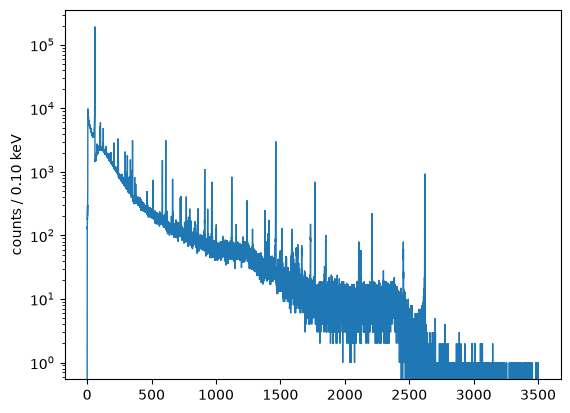

In [232]:


force_rebuild = True  # True per forzare il ricalcolo

spectrum_dir = Path("raw_energy_spectrum")
spectrum_dir.mkdir(parents=True, exist_ok=True)

spectrum_path = spectrum_dir / (
    f"{detector}_{measure}_{run_key}_spectrum.npz"
)


if spectrum_path.exists() and not force_rebuild:
    print(f"Carico: {spectrum_path}")

    with np.load(spectrum_path) as spectrum:
        counts_data = spectrum["counts"]
        bins = spectrum["bins"]

else:
    print(f"Creo: {spectrum_path}")
    # in questo modo salvo soltanto le informazioni che mi servono
    energy = lh5.read(
        "hit/cuspEmax_ctc_cal",
        file_names,
    ).nda
    bins = np.linspace(emin, emax, nbins + 1)
    counts_data, _ = np.histogram(energy, bins=bins)
    plt.stairs(counts_data, bins)
    plt.yscale('log')
    plt.ylabel(f'counts / {bins[1]-bins[0]:.2f} keV')
    print(bins[1]-bins[0])

    np.savez_compressed(
        spectrum_path,
        counts=counts_data,
        bins=bins,
    )

    del energy

In [233]:
print(f"Dimensione file: {spectrum_path.stat().st_size / 1024:.1f} KiB")

Dimensione file: 98.9 KiB


In [234]:
# ============================================================
# ANNOTAZIONE
# ============================================================
#detector = "V03421A"
source = db_data["source_position"]
card = db_data["daq_settings"]["flashcam"]["card_interface"]

annotation_measure = (
    f"Detector: {db_data['detector']}\n"
    f"Measure: {db_data['measurement']}\n"
    f"Run: {db_data['run']} "
    f"(T = {db_data['run_live_time_in_s'] / 3600:g} h)\n"
    f"Card interface: {card}\n"
    f"Voltage: {db_data['high_voltage_in_V']} V\n"
    f"z = {source['z_in_mm']:g} mm\n"
    f"r = {source['r_in_mm']:g} mm\n"
    f"φ = {source['phi_in_deg']:g}°"
)
annotation_measure

'Detector: V14673A\nMeasure: am_HS1_top_dlt\nRun: run0001 (T = 6 h)\nCard interface: efb3\nVoltage: 4900 V\nz = 5 mm\nr = 42 mm\nφ = 0°'

In [235]:
# Mantengo le energie che hai indicato
peaks = {
    "gamma_59p9keV": 59.9,
    "gamma_99keV": 99.0,
    "gamma_103keV": 103.0,
    "gamma_123p1keV": 123.1,
    "gamma_125p3keV": 125.3,
    "gamma_208p1keV": 208.1,
    "gamma_335p4keV": 335.4,
    "gamma_662p4keV": 662.4,
    "gamma":2615}

/tmp/ipykernel_850539/1331344204.py:38: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 1e7)


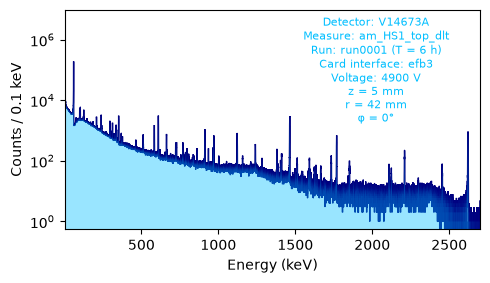

In [236]:
# ============================================================
# PLOT
# ============================================================
plt.figure(figsize=(5, 3))#, dpi = 300)

plt.stairs(
    counts_data,
    bins,
    color="navy",
)
plt.stairs(
    counts_data,
    bins,
    fill = True,
    alpha = 0.4,
    color="deepskyblue",
)

plt.annotate(
    annotation_measure,
    xy=(0.75, 0.97),
    xycoords="axes fraction",
    ha="center",
    va="top",
    multialignment="center",
    fontsize=8,
    zorder=8,
    color="deepskyblue",
)

# axvline non modifica i limiti verticali del grafico
#for energy in peaks.values():
#    plt.axvline(energy, color="red", linewidth=0.8)

#plt.axvline(2615, color="red", linewidth=0.8)

plt.yscale("log")
plt.ylim(0, 1e7)
plt.ylabel(f"Counts / {bins[1] - bins[0]:.1f} keV")
plt.xlabel("Energy (keV)")
plt.xlim(1, 2700)
plt.tight_layout()
plt.show()

# Fit

In [240]:
energy_range = (0, 65)
fit_range = (54, 63)
#energy_range = (0, 200)
#fit_range = (125, 175)
result_60 = fit_am60(counts_data, bins)

In [251]:
N60 = result_60['parameters'][0]

In [242]:
result_100 = fit_am_100(counts_data, bins)

In [253]:
N99 = result_100['parameters'][0]
N103 = result_100['parameters'][4]

In [210]:
dpi = 300

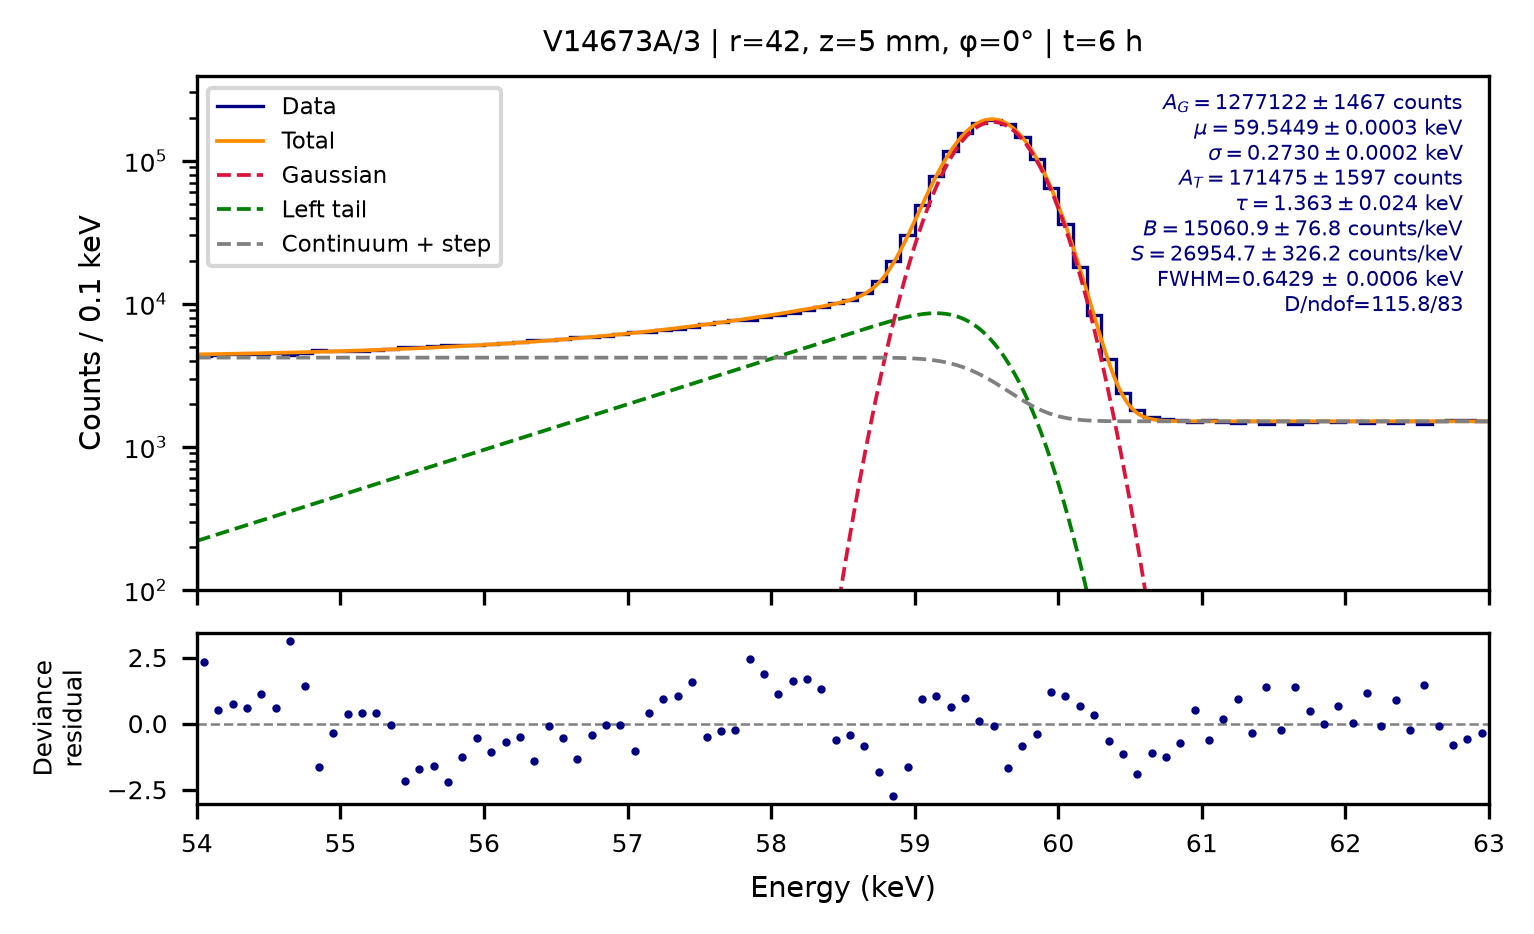

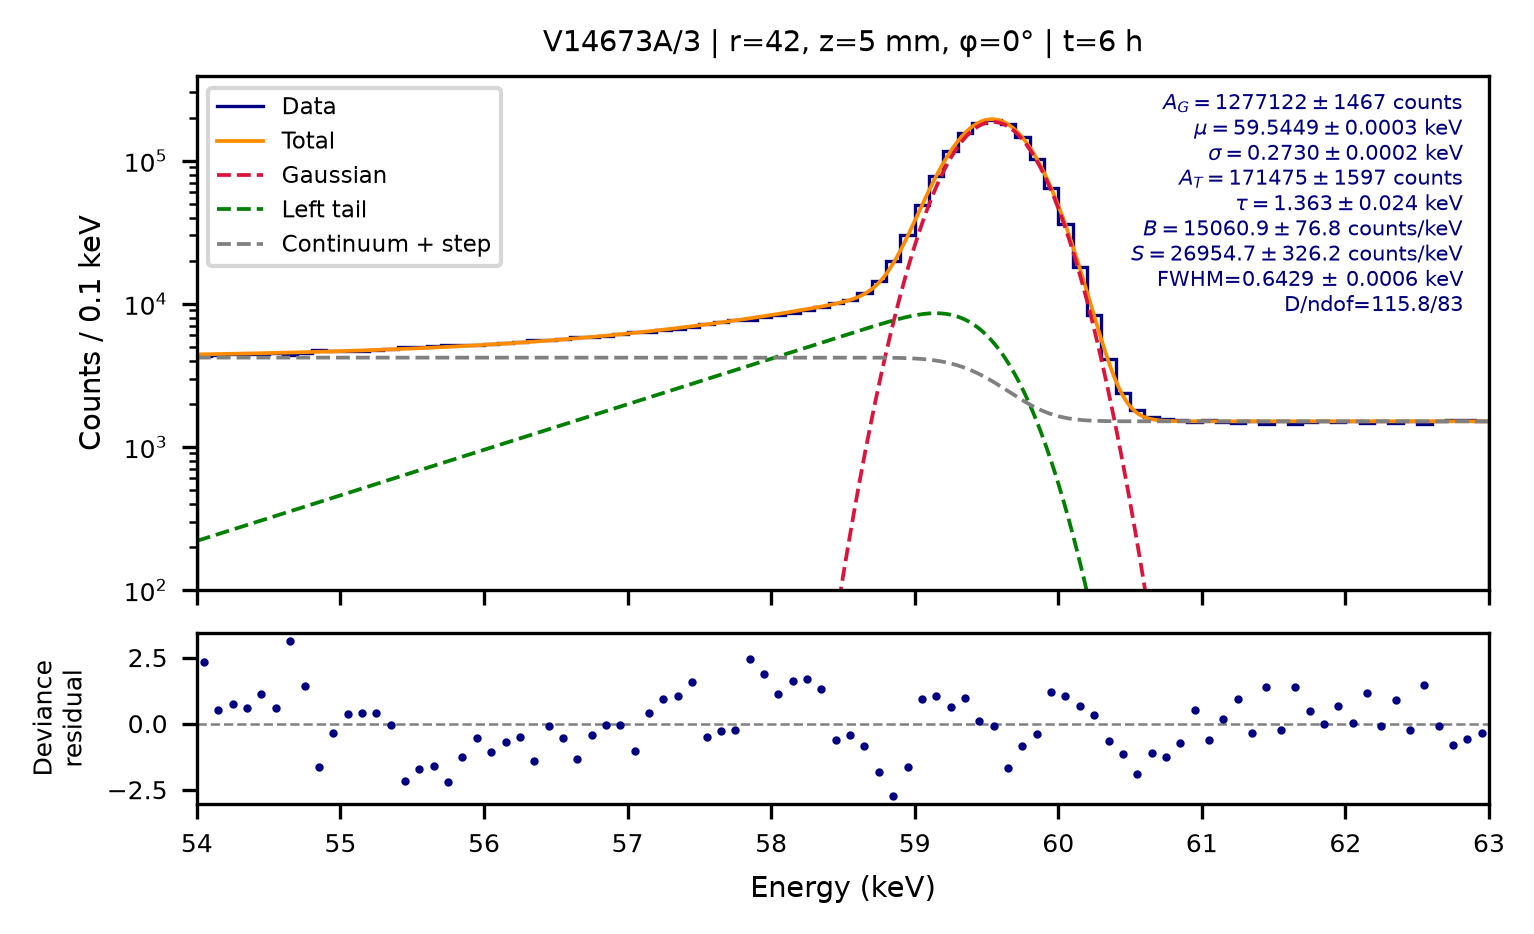

In [244]:
plot_am60_fit(result_60, detector, run, db_data)

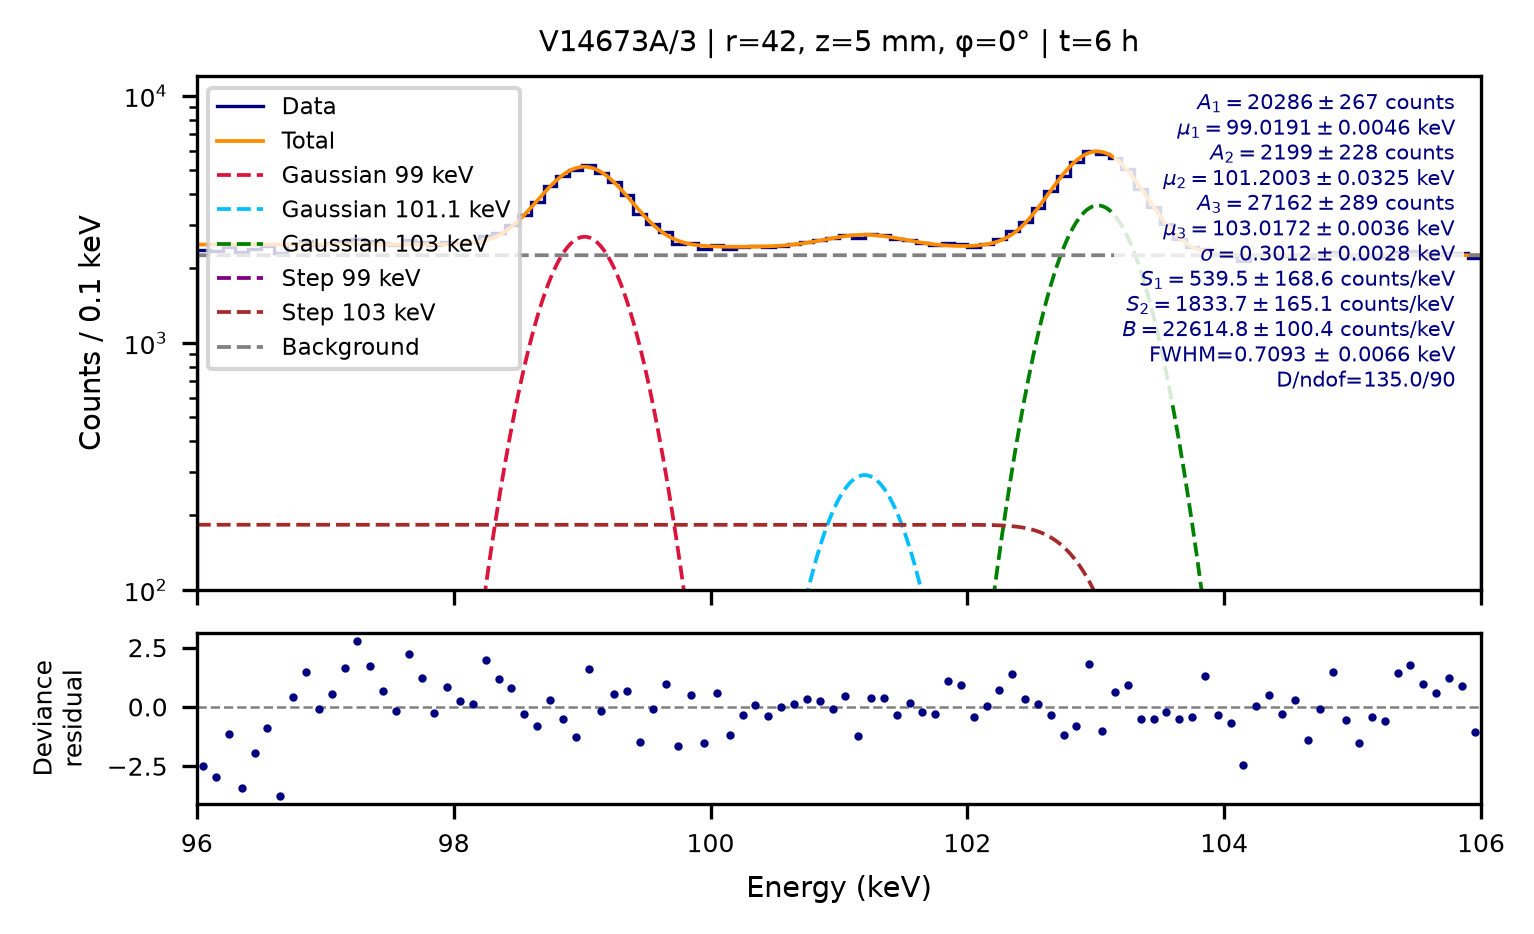

In [255]:
fig = plot_am100_fit(result_100, detector, run, db_data);


In [259]:
O60 = N60 / (N99 + N103)
print(f'experimental counting ratio {O60 :.2f}')

experimental counting ratio 26.92


# ALL DETECTORS

# sigmassss

In [153]:
# ============================================================
# CONFIGURATION
# ============================================================

base_dir = Path("/global/u2/r/ritaferi/HADES_DATA")

campaign = "c1"
measure = "am_HS1_top_dlt"

# Entrambe navy, con punti vicini:
# v1.1.0 = tondo; v1.2.1 = quadrato.
styles = {
    "v1.1.0": {
        "color": "navy",
        "marker": "o",
        "offset": -0.06,
    },
    "v1.2.1": {
        "color": "orange",
        "marker": "s",
        "offset": 0.06,
    },
}

runs = ["run0001", "run0002", "run0003"]

In [154]:

# ============================================================
# READ BOTH CSV FILES
# ============================================================

data = {}

for version in styles:
    path = (
        base_dir
        / "spectral_differences"
        / version
        / campaign
        / measure
        / "all_detectors_peak_area_normalized"
        / "fit_parameters.csv"
    )

    if not path.exists():
        print(f"File assente: {path}")
        data[version] = pd.DataFrame(
            columns=["detector", "run", "sigma", "sigma_error"]
        )
        continue

    df = pd.read_csv(path)

    required = {"detector", "run", "sigma", "sigma_error"}
    missing = required - set(df.columns)

    if missing:
        raise ValueError(f"Colonne mancanti in {path}: {missing}")

    for column in ["sigma", "sigma_error"]:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce",
        )

    valid = (
        np.isfinite(df["sigma"])
        & np.isfinite(df["sigma_error"])
        & (df["sigma"] > 0)
        & (df["sigma_error"] >= 0)
        & df["detector"].notna()
        & df["run"].notna()
    )

    data[version] = df.loc[valid].copy()

    print(
        f"{version}: {valid.sum()} valori validi, "
        f"{(~valid).sum()} esclusi"
    )




v1.1.0: 9 valori validi, 0 esclusi
v1.2.1: 52 valori validi, 0 esclusi


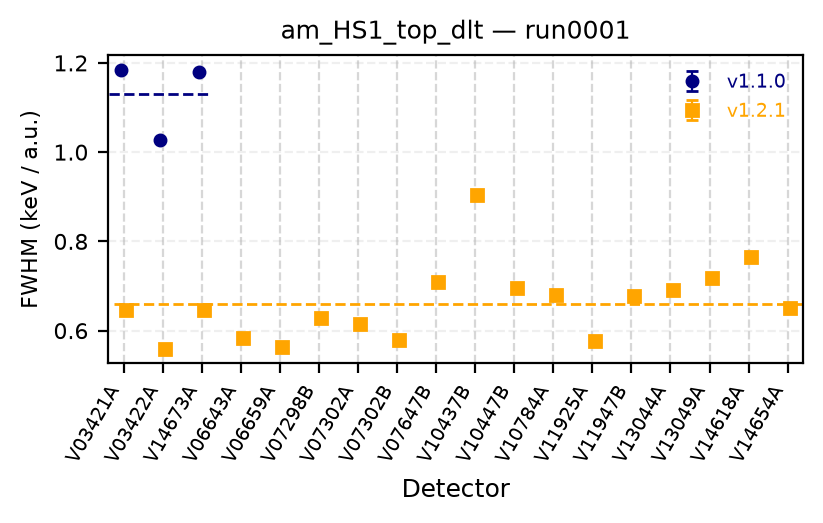

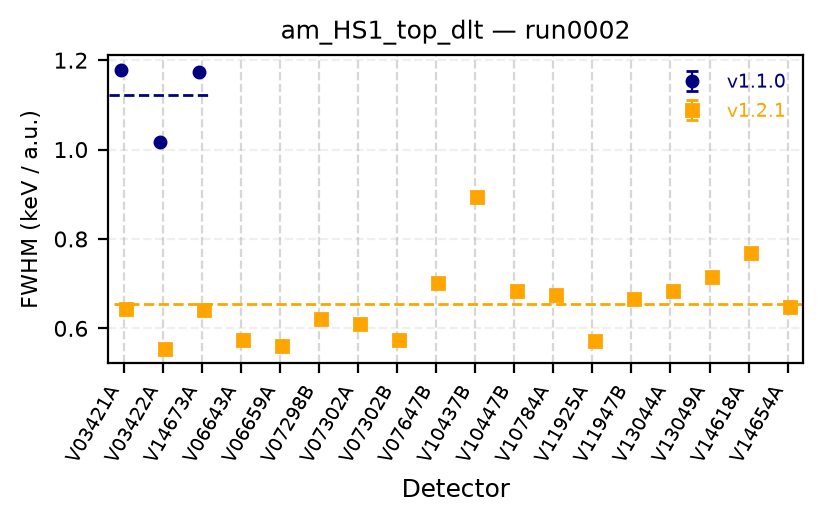

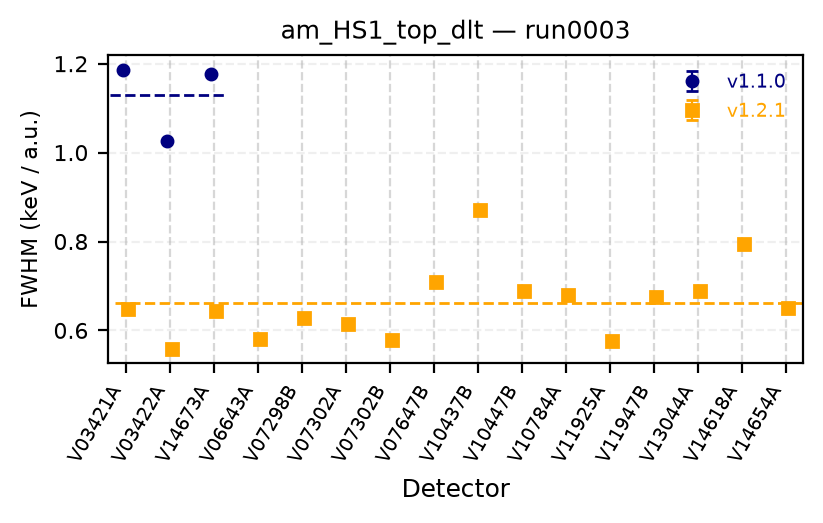

In [158]:
# ============================================================
# ONE PLOT PER RUN
# ============================================================

for run in runs:
    selected = {
        version: df.loc[df["run"] == run].copy()
        for version, df in data.items()
    }

    # Prima i detector presenti in v1.1.0.
    detectors_v1 = sorted(
        set(selected["v1.1.0"]["detector"])
    )

    # Poi quelli presenti solo in v1.2.1.
    other_detectors = sorted(
        set(selected["v1.2.1"]["detector"])
        - set(detectors_v1)
    )

    detectors = detectors_v1 + other_detectors

    if not detectors:
        print(f"Nessun dato per {run}")
        continue

    positions = {
        detector: index
        for index, detector in enumerate(detectors)
    }

    groups = [
        detectors[:3],
        detectors[3:],
    ]

    fig, ax = plt.subplots(
        figsize=(4, 2.5),
        dpi=200,
        layout="constrained",
    )

    for version, df in selected.items():
        if df.empty:
            continue

        style = styles[version]

        x = (
            df["detector"].map(positions).to_numpy()
            + style["offset"]
        )

        ax.errorbar(
            x,
            df["sigma"].to_numpy() * 2.35482,
            yerr=df["sigma_error"].to_numpy() * 2.35482,
            fmt=style["marker"],
            linestyle="none",
            color=style["color"],
            ecolor=style["color"],
            markersize=4,
            capsize=2,
            elinewidth=0.8,
            label=version,
        )

        ax.hlines(
            y=df["sigma"].mean() * 2.35482,
            xmin=x.min() - 0.3,
            xmax=x.max() + 0.3,
            color=style["color"],
            linestyle="--",
            linewidth=1,
        )

    ax.set_xticks(np.arange(len(detectors)))
    ax.set_xticklabels(
        detectors,
        rotation=60,
        ha="right",
        fontsize=7,
    )

    ax.set_xlim(-0.4, len(detectors) - 0.6)

    ax.set_xlabel("Detector", fontsize=9)
    ax.set_ylabel(
        r"FWHM (keV / a.u.)",
        fontsize=8,
    )
    ax.grid(alpha = 0.5, ls = '--') 
    ax.set_title(f"{measure} — {run}", fontsize=9)

    ax.tick_params(axis="y", labelsize=8)

    ax.legend(
        frameon=False,
        fontsize=7,
        labelcolor="linecolor",
    )

    ax.grid(axis="y", alpha=0.2)

    plt.show()
    plt.close(fig)

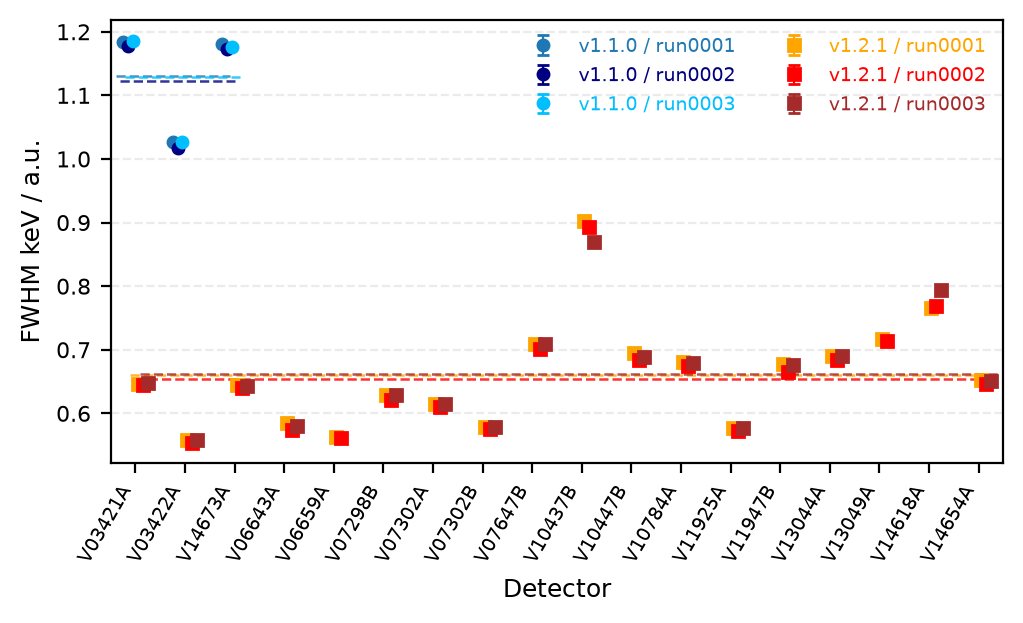

In [161]:
# Usa i DataFrame già caricati nel dizionario data.

runs = ["run0001", "run0002", "run0003"]

colors = {
    "v1.1.0": {
        "run0001": "tab:blue",
        "run0002": "navy",
        "run0003": "deepskyblue",
    },
    "v1.2.1": {
        "run0001": "orange",
        "run0002": "red",
        "run0003": "brown",
    },
}

markers = {
    "v1.1.0": "o",
    "v1.2.1": "s",
}

# Piccoli spostamenti per distinguere i sei punti.
offsets = {
    ("v1.1.0", "run0001"): -0.25,
    ("v1.1.0", "run0002"): -0.15,
    ("v1.1.0", "run0003"): -0.05,
    ("v1.2.1", "run0001"): 0.05,
    ("v1.2.1", "run0002"): 0.15,
    ("v1.2.1", "run0003"): 0.25,
}

# Considera soltanto i tre run richiesti.
selected = {
    version: df.loc[df["run"].isin(runs)].copy()
    for version, df in data.items()
}

# Raggruppa a sinistra i detector presenti in v1.1.0.
detectors_v1 = sorted(
    set(selected["v1.1.0"]["detector"])
)

other_detectors = sorted(
    set(selected["v1.2.1"]["detector"])
    - set(detectors_v1)
)

detectors = detectors_v1 + other_detectors

positions = {
    detector: index
    for index, detector in enumerate(detectors)
}

if not detectors:
    print("Nessun dato disponibile.")

else:
    fig, ax = plt.subplots(
        figsize=(5, 3),
        dpi=200,
        layout="constrained",
    )

    for version in ["v1.1.0", "v1.2.1"]:
        for run in runs:
            df = selected[version].loc[
                selected[version]["run"] == run
            ].copy()

            if df.empty:
                continue

            color = colors[version][run]

            x = (
                df["detector"].map(positions).to_numpy()
                + offsets[(version, run)]
            )

            fwhm = df["sigma"].to_numpy() * 2.35482
            fwhm_error = (
                df["sigma_error"].to_numpy() * 2.35482
            )

            ax.errorbar(
                x,
                fwhm,
                yerr=fwhm_error,
                fmt=markers[version],
                linestyle="none",
                color=color,
                ecolor=color,
                markersize=4,
                capsize=2,
                elinewidth=0.8,
                label=f"{version} / {run}",
            )

            ax.hlines(
                y=fwhm.mean(),
                xmin=x.min() - 0.15,
                xmax=x.max() + 0.15,
                color=color,
                linestyle="--",
                linewidth=0.9,
                alpha=0.8,
            )

    ax.set_xticks(np.arange(len(detectors)))
    ax.set_xticklabels(
        detectors,
        rotation=60,
        ha="right",
        fontsize=7,
    )

    ax.set_xlim(-0.5, len(detectors) - 0.5)

    ax.set_xlabel("Detector", fontsize=9)
    ax.set_ylabel("FWHM keV / a.u.", fontsize=9)
    
    ax.tick_params(axis="y", labelsize=8)

    ax.legend(
        frameon=False,
        fontsize=7,
        labelcolor="linecolor",
        ncol=2,
    )

    ax.grid(
        axis="y",
        alpha=0.25,
        linestyle="--",
    )

    plt.show()
    plt.close(fig)

# SOURCE POSITION

In [263]:
path = (
    Path("/global/u2/r/ritaferi/HADES_DATA")
    / "O60_experimental"
    / version
    / campaign
    / measure
    / "all_results.json"
)

# Coordinata da mostrare nel primo plot: "r", "z" oppure "phi".
position_axis = "z"

# False: conteggi N60; True: conteggi al secondo.
normalize_live_time = False

run_colors = {
    "run0001": "navy",
    "run0002": "orange",
    "run0003": "deepskyblue",
}

position_keys = {
    "r": ("r_in_mm", "Source r (mm)"),
    "z": ("z_in_mm", "Source z (mm)"),
    "phi": ("phi_in_deg", "Source φ (deg)"),
}

with path.open(encoding="utf-8") as stream:
    results = json.load(stream)


def finite_number(value):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return None
    return value if np.isfinite(value) else None



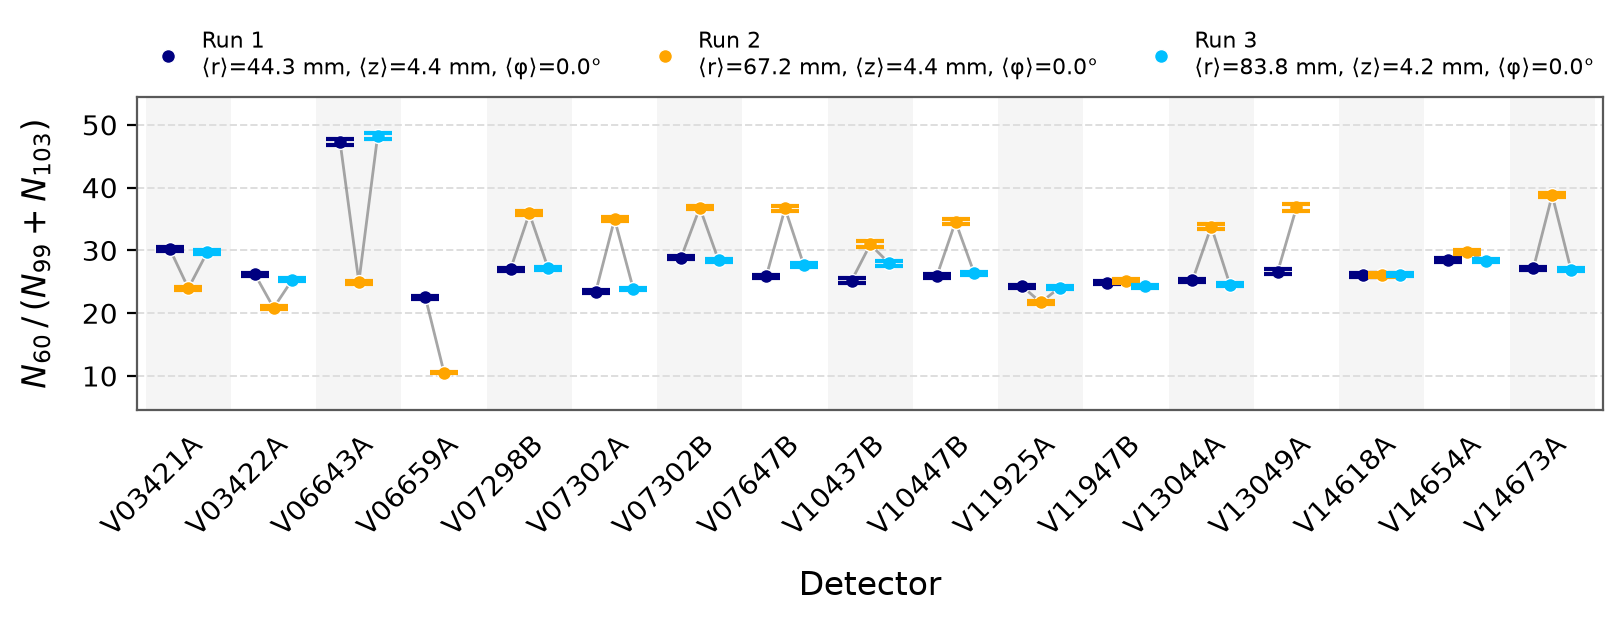

In [279]:

def finite_number(value):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return None
    return value if np.isfinite(value) else None


def mean_position(values, circular=False):
    if not values:
        return "N/A"

    if circular:
        angles = np.deg2rad(values)
        vector = np.mean(np.exp(1j * angles))

        if abs(vector) < 1e-10:
            return "N/A"

        mean = np.rad2deg(np.angle(vector)) % 360

        if np.isclose(mean, 360):
            mean = 0.0
    else:
        mean = np.mean(values)

    return f"{mean:.1f}"


# ============================================================
# RATIO FOR ALL DETECTORS, COLOURED BY RUN
# results: dizionario già caricato da all_results.json
# ============================================================

run_colors = {
    "run0001": "navy",
    "run0002": "orange",
    "run0003": "deepskyblue",
}

offsets = {
    "run0001": -0.22,
    "run0002": 0.0,
    "run0003": 0.22,
}

detector_list = sorted(
    detector
    for detector, detector_runs in results.items()
    if any(
        finite_number(
            (record.get("ratio") or {}).get("value")
        ) is not None
        for run, record in detector_runs.items()
        if run in run_colors
    )
)

with plt.rc_context({
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.edgecolor": "0.35",
    "axes.linewidth": 0.8,
}):
    fig_ratio, ax = plt.subplots(
        figsize=(8, 3),
        layout="constrained",
        dpi=200,
    )

    # Bande alternate per distinguere i detector.
    for index in range(len(detector_list)):
        if index % 2 == 0:
            ax.axvspan(
                index - 0.5,
                index + 0.5,
                color="0.96",
                linewidth=0,
                zorder=0,
            )

    for index, detector in enumerate(detector_list):
        x_line, y_line = [], []

        for run in run_colors:
            record = results[detector].get(run)
            if not record:
                continue

            value = finite_number(
                (record.get("ratio") or {}).get("value")
            )

            if value is None:
                continue

            x_line.append(index + offsets[run])
            y_line.append(value)

        if len(x_line) >= 2:
            ax.plot(
                x_line,
                y_line,
                color="0.5",
                linewidth=1,
                alpha=0.7,
                zorder=2,
            )

    for run, color in run_colors.items():
        x, y, errors = [], [], []

        positions = {
            "r_in_mm": [],
            "z_in_mm": [],
            "phi_in_deg": [],
        }

        for index, detector in enumerate(detector_list):
            record = results[detector].get(run)
            if not record:
                continue

            ratio = record.get("ratio") or {}
            value = finite_number(ratio.get("value"))
            error = finite_number(ratio.get("error"))

            if value is None:
                continue

            x.append(index + offsets[run])
            y.append(value)
            errors.append(
                error
                if error is not None and error >= 0
                else np.nan
            )

            # Posizioni dei soli detector mostrati per questo run.
            pos = (
                (record.get("metadata") or {}).get("source_position")
                or {}
            )

            for key in positions:
                coordinate = finite_number(pos.get(key))
                if coordinate is not None:
                    positions[key].append(coordinate)

        if not x:
            continue

        x = np.asarray(x)
        y = np.asarray(y)
        errors = np.asarray(errors)

        r_mean = mean_position(positions["r_in_mm"])
        z_mean = mean_position(positions["z_in_mm"])
        phi_mean = mean_position(
            positions["phi_in_deg"],
            circular=True,
        )

        run_label = (
            f"Run {int(run[3:])}\n"
            f"⟨r⟩={r_mean} mm, "
            f"⟨z⟩={z_mean} mm, "
            f"⟨φ⟩={phi_mean}°"
        )

        # Tutti i punti, anche quelli senza incertezza disponibile.
        ax.plot(
            x,
            y,
            linestyle="none",
            marker="o",
            color=color,
            markersize=5,
            markeredgecolor="white",
            markeredgewidth=0.5,
            label=run_label,
            zorder=4,
        )

        # Barre d'errore solo dove l'incertezza è disponibile.
        valid_errors = np.isfinite(errors)

        ax.errorbar(
            x[valid_errors],
            y[valid_errors],
            yerr=errors[valid_errors],
            fmt="none",
            ecolor=color,
            elinewidth=1.5,
            capsize=5,
            capthick=1.5,
            zorder=5,
        )

    ax.set_xticks(np.arange(len(detector_list)))
    ax.set_xticklabels(
        detector_list,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )

    if detector_list:
        ax.set_xlim(-0.6, len(detector_list) - 0.4)

    ax.set_ylabel(
        r"$N_{60}\,/\,(N_{99}+N_{103})$",
        labelpad=10,
    )
    ax.set_xlabel("Detector", labelpad=10)

    ax.set_axisbelow(True)
    ax.grid(
        axis="y",
        color="0.87",
        linewidth=0.7,
        linestyle="--",
    )

    ax.tick_params(axis="x", length=0, pad=8)
    ax.tick_params(axis="y", direction="out")
    ax.margins(y=0.15)

    if detector_list:
        ax.legend(
            loc="lower left",
            bbox_to_anchor=(0, 1.02, 1, 0),
            mode="expand",
            ncol=3,
            fontsize=8,
            frameon=False,
            borderaxespad=0,
            handletextpad=0.5,
        )

    plt.show()

# Sims

In [ ]:
#run = "run0001"
config_geom = deepcopy(configuration[run])

gdml_file = os.path.join(
    output_dir, f"{detector}_{measure}_{run}.gdml"
)

if os.path.isfile(gdml_file):
    reg = gdml.Reader(gdml_file).getRegistry()
    print(f"GDML già presente, caricato: {gdml_file}")
else:
    reg = pygeomhades.core.construct(config_geom)
    os.makedirs(output_dir, exist_ok=True)
    write_pygeom(reg, gdml_file)
    print(f"GDML creato: {gdml_file}")

In [24]:

placements = collect_global_placements(reg.getWorldVolume())

detector_name = find_germanium_detector(reg)

components = {
    "cavity_lv": {
        "label": "cavity",
        "color": "tab:blue"
    },
    "Wrap": {
        "label": "wrap",
        "color": "tab:orange"
    },
    "Holder": {
        "label": "holder",
        "color": "tab:green"
    },
    detector_name: {
        "label": "detector",
        "color": "tab:red"
    },
    "Cryostat": {
        "label": "cryo",
        "color": "tab:purple"
    },
}

fig, ax = plt.subplots(figsize=(4,8))

for logical_name, style in components.items():

    if logical_name not in placements:
        print(f"Volume non trovato: {logical_name}")
        continue

    # Se esistono più copie, le disegna tutte
    for index, placement in enumerate(placements[logical_name]):

        lv = placement["logical_volume"]
        matrix = placement["matrix"]

        try:
            r_local, z_local = get_profile(lv.solid)
        except TypeError as error:
            print(error)
            continue

        radius, height = transform_profile(
            r_local,
            z_local,
            matrix
        )

        # Una sola voce in legenda per componente
        label = style["label"] if index == 0 else None

        ax.plot(
            radius,
            height,
            color=style["color"],
            linewidth=1.3,
            label=label
        )

ax.set_title(detector_name, fontsize=16)
ax.set_xlabel("radius (mm)")
ax.set_ylabel("height (mm)")

ax.set_xlim(left=-2)
ax.set_aspect("equal", adjustable="box")

ax.grid(alpha=0.15)
ax.legend(loc = 'lower right')

plt.tight_layout()
plt.show()

NameError: name 'collect_global_placements' is not defined

In [ ]:
peaks = {
    "gamma_59p9keV": 59.9,
    "gamma_99keV": 99.0,
    "gamma_103keV": 103.0,
    "gamma_123p1keV": 123.1,
    "gamma_125p3keV": 125.3,
    "gamma_208p1keV": 208.1,
    "gamma_335p4keV": 335.4,
    "gamma_662p4keV": 662.4,
}

N_sim = 1_000
force_rerun = False

os.makedirs(output_dir, exist_ok=True)
simulation_files = {}

for name, energy_keV in peaks.items():

    output_file = os.path.join(
        output_dir,
        f"{detector}_{measure}_{run}_{name}.lh5"
    )

    if os.path.isfile(output_file) and not force_rerun:
        simulation_files[name] = output_file
        print(f"✅ {name}: uso il file esistente → {output_file}")
        continue

    macro = [
        "/RMG/Manager/Logging/LogLevel summary",
        "/RMG/Processes/HadronicPhysics Shielding",
        f"/RMG/Geometry/RegisterDetector Germanium {detector} 1",
        "/RMG/Output/NtupleUseVolumeName true",
        "/RMG/Output/NtuplePerDetector false",
        "/run/initialize",
        "/RMG/Generator/Confine Volume",
        "/RMG/Generator/Confinement/Physical/AddVolume Source_PV",
        "/RMG/Generator/Select GPS",
        "/gps/particle gamma",
        "/gps/ene/type Mono",
        f"/gps/energy {energy_keV} keV",
        "/gps/ang/type iso",
        f"/run/beamOn {N_sim}",
    ]

    print(f"▶ {name}: avvio simulazione → {output_file}")

    try:
        remage_run(
            macros=macro,
            gdml_files=gdml_file,
            output=output_file,
            overwrite_output=True,
        )
        simulation_files[name] = output_file
        print(f"✅ {name}: simulazione completata")

    except Exception as e:
        print(f"❌ {name}: {e}")

print("\nFile disponibili:", simulation_files)

In [ ]:
N_sim_by_peak = {}
energies = ["gamma_59p9keV", "gamma_99keV","gamma_103keV",
    "gamma_123p1keV",
    "gamma_125p3keV",
    "gamma_208p1keV",
    "gamma_335p4keV"]

for name in energies:
    filename = os.path.join(
        output_dir, f"{detector}_{measure}_{run}_{name}.lh5"
    )

    obj = lh5.read("number_of_simulated_events", filename)

    # Compatibilità con versioni che restituiscono una tupla
    if isinstance(obj, tuple):
        obj = obj[0]

    N_sim_by_peak[name] = int(obj.value)
    print(f"{name}: {N_sim_by_peak[name]:,} eventi simulati")

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
has_counts = False

for i, (name, energy_keV) in enumerate(peaks.items()):

    filename = simulation_files.get(
        name,
        os.path.join(
            output_dir,
            f"{detector}_{measure}_{run}_{name}.lh5"
        )
    )

    print("PATH:", filename, "| esiste:", os.path.isfile(filename))

    try:
        data = lh5.read_as("stp/germanium", filename, "ak")
        energy = ak.to_numpy(ak.sum(data.edep, axis=-1))
        energy = energy[energy > 0]

        counts, _ = np.histogram(energy, bins=bins)

        if counts.sum() == 0:
            print(f"{name}: nessun deposito nell'intervallo del grafico")
            continue

        ax.stairs(
            counts,
            bins,
            #color=colors[i % len(colors)],
            label=f"{energy_keV:g} keV"
        )
        has_counts = True

    except Exception:
        print(f"Errore durante la lettura o il grafico di {name}:")
        traceback.print_exc()

if has_counts:
    ax.set_xlabel("Energy deposited [keV]")
    ax.set_ylabel("Counts / 1 keV")
    ax.set_xlim(emin, emax)
    ax.set_yscale("log")
    ax.legend(title="Gamma generato")
    fig.tight_layout()
    plt.show()
else:
    plt.close(fig)
    print("Nessun conteggio da mostrare")

In [ ]:
BR = {
    "gamma_59p9keV":  0.359,
    "gamma_99keV":    2.03e-4,
    "gamma_103keV":   1.95e-4,
    "gamma_123p1keV": 1.00e-5,
    "gamma_125p3keV": 4.08e-5,
    "gamma_208p1keV": 7.91e-6,
    "gamma_335p4keV": 4.96e-6,
}


In [ ]:

activity = 4330e3  # Bq: valore nominale comune alla misura

counts_theory = np.zeros(len(bins) - 1)
counts_smeared = np.zeros(len(bins) - 1)

for name, br in BR.items():

    filename = os.path.join(
        output_dir, f"{detector}_{measure}_{run}_{name}.lh5"
    )

    # Gli errori di lettura vengono mostrati, evitando somme incomplete
    data = lh5.read_as("stp/germanium", filename, "ak")
    energy = ak.to_numpy(ak.sum(data.edep, axis=-1))
    energy = energy[energy > 0]

    if len(energy) == 0:
        print(f"{name}: nessun deposito positivo di energia")
        continue

    energy_smeared = ak.to_numpy(
        reboost.math.stats.gaussian_sample(energy, sigma=1)
    )

    N_sim = N_sim_by_peak[name]
    if N_sim <= 0:
        raise ValueError(f"{name}: N_sim deve essere positivo")

    # BR applicato una sola volta, nel peso
    peso = activity * time_measurement * br / N_sim
    weights = np.full(len(energy), peso)

    counts_iso, _ = np.histogram(
        energy, bins=bins, weights=weights
    )
    counts_iso_smeared, _ = np.histogram(
        energy_smeared, bins=bins, weights=weights
    )

    counts_theory += counts_iso
    counts_smeared += counts_iso_smeared

    print(f"{name}: N_sim = {N_sim:,}, peso = {peso:.6g}")

counts_MC = counts_smeared